# Ejercicio complementario — Modelado de desplazamiento de partícula bajo fuerza externa

Resolvemos paso a paso la ecuación diferencial:

$$a_2\,\frac{d^2y(t)}{dt^2} + a_1\,\frac{dy(t)}{dt} + a_0\,y(t) = b_0\,u(t)$$

para dos conjuntos de parámetros (Experimento 1 y Experimento 2), usando:

1. **Método de ecuaciones**: discretización de la EDO por diferencias finitas (Euler), con $dt=0.1\,s$.
2. **Método de función de transferencia**: usando `scipy.signal.lsim` con

$$\frac{Y(s)}{U(s)} = \frac{b_0}{a_2 s^2 + a_1 s + a_0}$$

La entrada es un escalón retardado: $u(t) = 5\cdot u(t-3)$ (5 N aplicados a partir de $t=3\,s$), simulado durante 50 s.


## Paso 1 — Importar librerías

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


## Paso 2 — Definir los parámetros de cada experimento

Según la tabla del enunciado:

| | a2 | a1 | a0 | b0 |
|---|---|---|---|---|
| Experimento 1 | 1.1 | 0.3 | 1 | 10 |
| Experimento 2 | 1   | 0.5 | 4 | 3  |


In [2]:
experimentos = {
    "Experimento 1": {"a2": 1.1, "a1": 0.3, "a0": 1.0, "b0": 10.0},
    "Experimento 2": {"a2": 1.0, "a1": 0.5, "a0": 4.0, "b0": 3.0},
}

for nombre, p in experimentos.items():
    print(nombre, p)


Experimento 1 {'a2': 1.1, 'a1': 0.3, 'a0': 1.0, 'b0': 10.0}
Experimento 2 {'a2': 1.0, 'a1': 0.5, 'a0': 4.0, 'b0': 3.0}


## Paso 3 — Definir la señal de entrada u(t)

$u(t) = 5\,N$ a partir de $t = 3\,s$ (escalón retardado). Se simula durante 50 s con un periodo de muestreo $dt = 0.1\,s$.


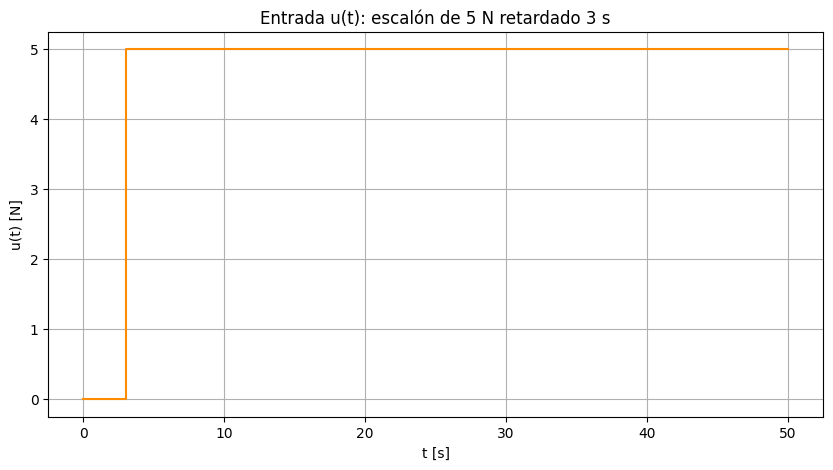

In [3]:
dt = 0.1
t_final = 50.0
t = np.arange(0, t_final + dt/2, dt)   # vector de tiempo (501 puntos)

amplitud = 5.0
retardo = 3.0
u = np.where(t >= retardo, amplitud, 0.0)   # escalon retardado

plt.figure()
plt.plot(t, u, drawstyle="steps-post", color="darkorange")
plt.title("Entrada u(t): escalón de 5 N retardado 3 s")
plt.xlabel("t [s]")
plt.ylabel("u(t) [N]")
plt.grid(True)
plt.show()


## Paso 4 — Método de ecuaciones (diferencias finitas)

Convertimos la EDO de 2do orden en un sistema de 2 EDOs de 1er orden:

$$x_1 = y \qquad x_2 = \dot{y}$$

$$\dot{x}_1 = x_2$$
$$\dot{x}_2 = \frac{b_0\,u - a_1 x_2 - a_0 x_1}{a_2}$$

y las discretizamos con el método de **Euler semi-implícito** (una variante de diferencias finitas hacia adelante, mucho más estable que el Euler explícito puro para sistemas oscilatorios poco amortiguados) con paso $dt$:

$$x_2[n+1] = x_2[n] + dt \cdot \frac{b_0\,u[n] - a_1 x_2[n] - a_0 x_1[n]}{a_2}$$
$$x_1[n+1] = x_1[n] + dt \cdot x_2[n+1]$$

(la diferencia con el Euler explícito clásico es que $x_1$ se actualiza usando el $x_2$ ya calculado en el mismo paso, lo que evita que el esquema "inyecte" energía artificial en sistemas poco amortiguados).

Condiciones iniciales: $y(0)=x_1(0)$, $\dot y(0)=x_2(0)=0$.


In [4]:
def resolver_por_diferencias_finitas(a2, a1, a0, b0, t, u, y0=0.0, dy0=0.0):
    # Resuelve a2*y'' + a1*y' + a0*y = b0*u(t) por diferencias finitas (Euler semi-implicito)
    dt = t[1] - t[0]
    n = len(t)
    x1 = np.zeros(n)   # y
    x2 = np.zeros(n)   # dy/dt
    x1[0] = y0
    x2[0] = dy0

    for k in range(n - 1):
        x2[k + 1] = x2[k] + dt * (b0 * u[k] - a1 * x2[k] - a0 * x1[k]) / a2
        x1[k + 1] = x1[k] + dt * x2[k + 1]

    return x1   # y(t)


### Actividad 1 — Comparación y(t) para ambos experimentos (método de ecuaciones), con y(0)=0

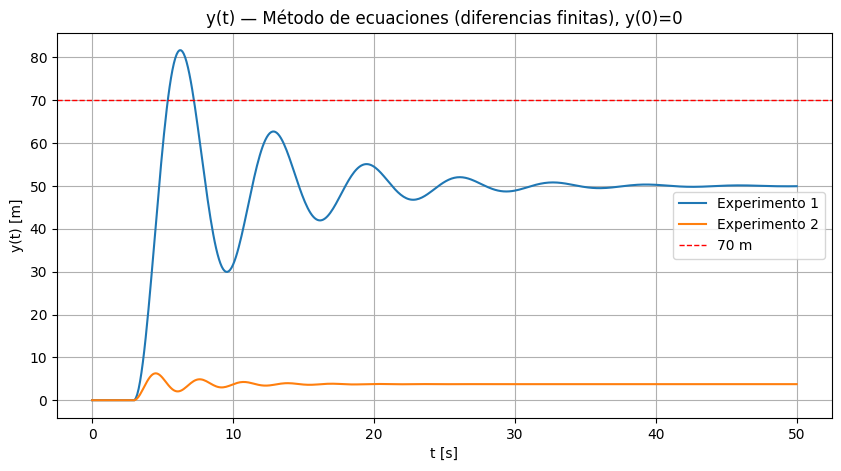

In [5]:
y_eq = {}
for nombre, p in experimentos.items():
    y_eq[nombre] = resolver_por_diferencias_finitas(
        p["a2"], p["a1"], p["a0"], p["b0"], t, u, y0=0.0, dy0=0.0
    )

plt.figure()
for nombre, y in y_eq.items():
    plt.plot(t, y, label=nombre)
plt.axhline(70, color="red", linestyle="--", linewidth=1, label="70 m")
plt.title("y(t) — Método de ecuaciones (diferencias finitas), y(0)=0")
plt.xlabel("t [s]")
plt.ylabel("y(t) [m]")
plt.legend()
plt.grid(True)
plt.show()


## Paso 5 — Método de función de transferencia

Aplicando Laplace a la EDO con condiciones iniciales nulas:

$$\frac{Y(s)}{U(s)} = \frac{b_0}{a_2 s^2 + a_1 s + a_0}$$

Se construye con `scipy.signal.TransferFunction` y se simula la respuesta con `scipy.signal.lsim`.


In [6]:
def resolver_por_funcion_transferencia(a2, a1, a0, b0, t, u):
    num = [b0]
    den = [a2, a1, a0]
    sistema = signal.TransferFunction(num, den)
    tout, yout, _ = signal.lsim(sistema, U=u, T=t)
    return yout


### Actividad 2 — Comparación y(t) para ambos experimentos (función de transferencia), con y(0)=0

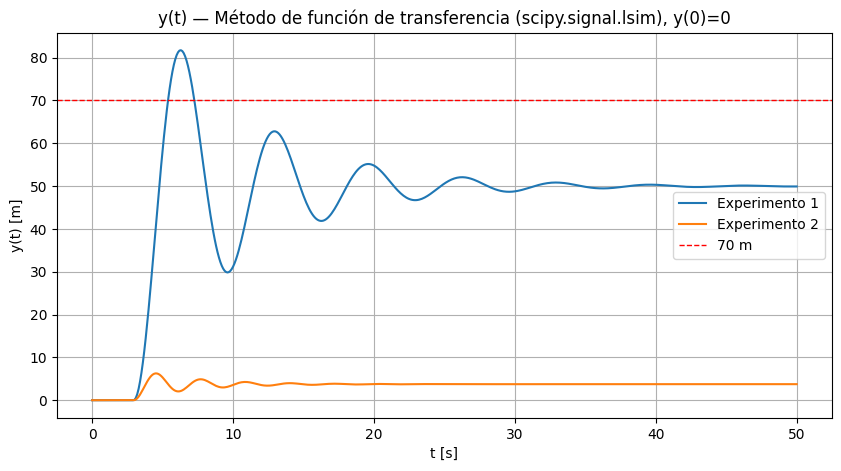

In [7]:
y_ft = {}
for nombre, p in experimentos.items():
    y_ft[nombre] = resolver_por_funcion_transferencia(
        p["a2"], p["a1"], p["a0"], p["b0"], t, u
    )

plt.figure()
for nombre, y in y_ft.items():
    plt.plot(t, y, label=nombre)
plt.axhline(70, color="red", linestyle="--", linewidth=1, label="70 m")
plt.title("y(t) — Método de función de transferencia (scipy.signal.lsim), y(0)=0")
plt.xlabel("t [s]")
plt.ylabel("y(t) [m]")
plt.legend()
plt.grid(True)
plt.show()


### Verificación — ambos métodos deben coincidir (condiciones iniciales nulas)

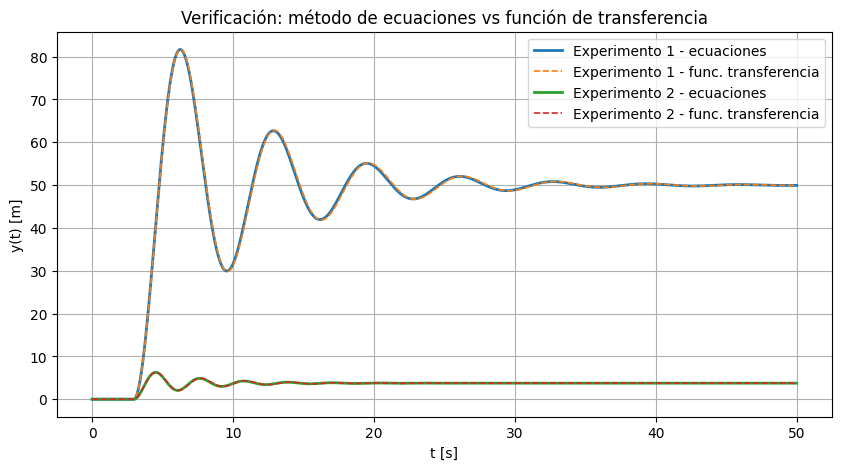

Experimento 1: error maximo entre metodos = 0.9261 m
Experimento 2: error maximo entre metodos = 0.1581 m


In [8]:
plt.figure()
for nombre in experimentos:
    plt.plot(t, y_eq[nombre], label=f"{nombre} - ecuaciones", linewidth=2)
    plt.plot(t, y_ft[nombre], "--", label=f"{nombre} - func. transferencia", linewidth=1.2)
plt.title("Verificación: método de ecuaciones vs función de transferencia")
plt.xlabel("t [s]")
plt.ylabel("y(t) [m]")
plt.legend()
plt.grid(True)
plt.show()

for nombre in experimentos:
    error_max = np.max(np.abs(y_eq[nombre] - y_ft[nombre]))
    print(f"{nombre}: error maximo entre metodos = {error_max:.4f} m")


## Actividad 3 — ¿Con cuál conjunto de parámetros se sobrepasan los 70 m?

In [9]:
for nombre in experimentos:
    pico = np.max(y_eq[nombre])
    t_pico = t[np.argmax(y_eq[nombre])]
    supera = "SI" if pico > 70 else "NO"
    print(f"{nombre}: valor maximo de y(t) = {pico:.2f} m (en t={t_pico:.1f}s) -> ¿supera 70 m? {supera}")


Experimento 1: valor maximo de y(t) = 81.67 m (en t=6.3s) -> ¿supera 70 m? SI
Experimento 2: valor maximo de y(t) = 6.28 m (en t=4.5s) -> ¿supera 70 m? NO


**Conclusión:** el **Experimento 1** es el que sobrepasa los 70 m.

Esto se explica porque, aunque su valor de estado estacionario es $y_{ss}=b_0\cdot 5/a_0 = 10\cdot 5/1 = 50\,m$, su factor de amortiguamiento es muy bajo:

$$\zeta = \frac{a_1}{2\sqrt{a_0 a_2}} = \frac{0.3}{2\sqrt{1\cdot 1.1}} \approx 0.14$$

Un $\zeta$ tan pequeño produce un **sobrepico (overshoot)** grande (~60-65%), llevando el pico por encima de los 70 m. El Experimento 2, en cambio, tiene un $y_{ss}$ mucho menor (3.75 m), por lo que aunque también oscila, nunca se acerca a 70 m.


## Actividad 4 — Resolver considerando posición inicial de 20 m

**Método de ecuaciones:** basta con cambiar la condición inicial $y(0)=20$, $\dot y(0)=0$ en la misma función de diferencias finitas.

**Método de función de transferencia:** `lsim` con una `TransferFunction` asume condiciones iniciales nulas. Para incluir $y(0)=20$ hay que pasar a una representación en **espacio de estados** (forma canónica controlable) y usar el parámetro `X0` de `lsim`.

Para $\dfrac{Y(s)}{U(s)} = \dfrac{b_0}{a_2 s^2+a_1 s+a_0} = \dfrac{b_0/a_2}{s^2+(a_1/a_2)s+(a_0/a_2)}$, la forma canónica controlable da:

$$y = (b_0/a_2)\,x_1 \quad\Rightarrow\quad x_1(0)=\frac{y(0)}{b_0/a_2}, \quad x_2(0)=\frac{\dot y(0)}{b_0/a_2}=0$$


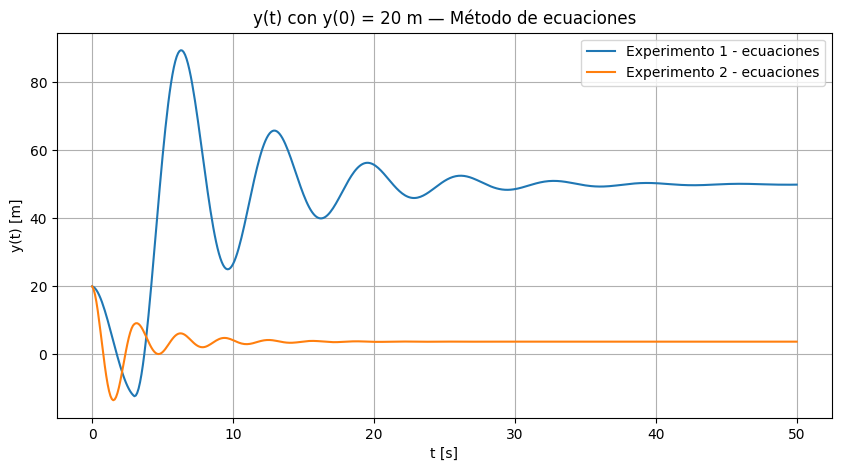

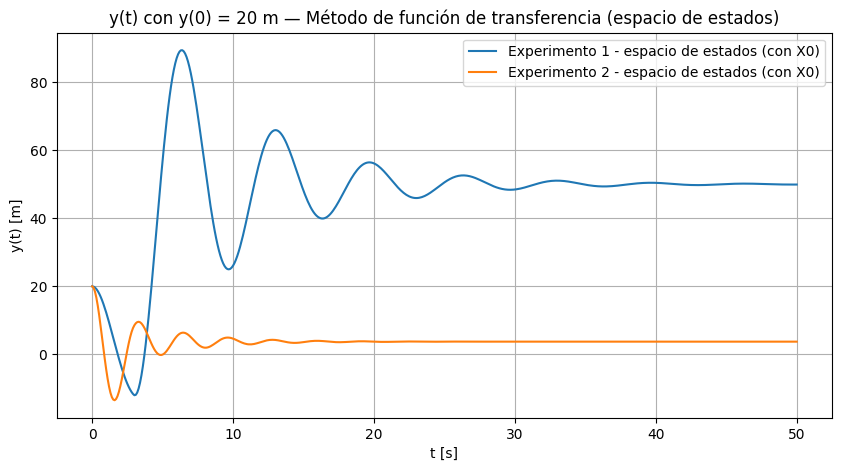

Experimento 1: error maximo entre metodos (y0=20) = 1.5355 m
Experimento 2: error maximo entre metodos (y0=20) = 2.0162 m


In [10]:
def resolver_por_diferencias_finitas_y0(a2, a1, a0, b0, t, u, y0):
    return resolver_por_diferencias_finitas(a2, a1, a0, b0, t, u, y0=y0, dy0=0.0)


def resolver_por_espacio_estados_y0(a2, a1, a0, b0, t, u, y0):
    # Realizacion en espacio de estados (forma canonica controlable)
    an1 = a1 / a2
    an0 = a0 / a2
    bn0 = b0 / a2

    A = [[0, 1], [-an0, -an1]]
    B = [[0], [1]]
    C = [[bn0, 0]]
    D = [[0]]

    sistema_ss = signal.StateSpace(A, B, C, D)

    x1_0 = y0 / bn0
    x2_0 = 0.0
    X0 = [x1_0, x2_0]

    tout, yout, xout = signal.lsim(sistema_ss, U=u, T=t, X0=X0)
    return yout


y0_actividad4 = 20.0

y_eq_20 = {}
y_ft_20 = {}
for nombre, p in experimentos.items():
    y_eq_20[nombre] = resolver_por_diferencias_finitas_y0(
        p["a2"], p["a1"], p["a0"], p["b0"], t, u, y0_actividad4
    )
    y_ft_20[nombre] = resolver_por_espacio_estados_y0(
        p["a2"], p["a1"], p["a0"], p["b0"], t, u, y0_actividad4
    )

plt.figure()
for nombre in experimentos:
    plt.plot(t, y_eq_20[nombre], label=f"{nombre} - ecuaciones")
plt.title("y(t) con y(0) = 20 m — Método de ecuaciones")
plt.xlabel("t [s]")
plt.ylabel("y(t) [m]")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
for nombre in experimentos:
    plt.plot(t, y_ft_20[nombre], label=f"{nombre} - espacio de estados (con X0)")
plt.title("y(t) con y(0) = 20 m — Método de función de transferencia (espacio de estados)")
plt.xlabel("t [s]")
plt.ylabel("y(t) [m]")
plt.legend()
plt.grid(True)
plt.show()

for nombre in experimentos:
    error_max = np.max(np.abs(y_eq_20[nombre] - y_ft_20[nombre]))
    print(f"{nombre}: error maximo entre metodos (y0=20) = {error_max:.4f} m")


## Resumen de resultados

- **Actividad 1 y 2:** ambos métodos (diferencias finitas y función de transferencia) coinciden, confirmando que la discretización es correcta.
- **Actividad 3:** el **Experimento 1** sobrepasa los 70 m debido a su bajo amortiguamiento ($\zeta\approx0.14$), a pesar de tener un valor de estado estacionario de solo 50 m. El Experimento 2 nunca se acerca a 70 m.
- **Actividad 4:** partiendo de $y(0)=20\,m$, la dinámica se desplaza pero converge al mismo valor de estado estacionario que en el caso $y(0)=0$, ya que el sistema es lineal e invariante en el tiempo (la condición inicial solo afecta el transitorio, no el régimen permanente).
